<a href="https://colab.research.google.com/github/hugolo000/DigitalImage_PROJECT/blob/main/notebooks/01_data_extraction_and_eda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import os
import zipfile
import urllib.request
from pathlib import Path

# Step 1: Define dataset source URL and output directories
DATASET_URL = "https://github.com/alexgkendall/SegNet-Tutorial/archive/refs/heads/master.zip"
DATA_DIR = Path("./data")
RAW_ZIP_PATH = DATA_DIR / "camvid_raw.zip"
EXTRACTED_DIR = DATA_DIR / "extracted"

# Step 2: Download the zip archive if it does not exist locally
DATA_DIR.mkdir(parents=True, exist_ok=True)
if not RAW_ZIP_PATH.exists():
    print("[INFO] Downloading CamVid dataset...")
    urllib.request.urlretrieve(DATASET_URL, RAW_ZIP_PATH)
    print("[INFO] Download complete.")

# Step 3: Extract the dataset archive
if not EXTRACTED_DIR.exists():
    print("[INFO] Unzipping dataset files...")
    with zipfile.ZipFile(RAW_ZIP_PATH, 'r') as zip_ref:
        zip_ref.extractall(EXTRACTED_DIR)
    print("[INFO] Extraction complete.")

# Define base path to CamVid data folder
CAMVID_PATH = EXTRACTED_DIR / "SegNet-Tutorial-master" / "CamVid"
print(f"[INFO] CamVid root path: {CAMVID_PATH}")

[INFO] Downloading CamVid dataset...
[INFO] Download complete.
[INFO] Unzipping dataset files...
[INFO] Extraction complete.
[INFO] CamVid root path: data/extracted/SegNet-Tutorial-master/CamVid


2

In [8]:
import os
import pandas as pd
from pathlib import Path

def load_camvid_split(txt_filename: str, base_dir: Path) -> pd.DataFrame:
    """
    Parses a CamVid split text file by extracting only the parent directory
    and filename, ignoring any hardcoded absolute paths in the original .txt.
    """
    txt_path = base_dir / "CamVid" / txt_filename
    image_paths = []
    mask_paths = []

    with open(txt_path, 'r') as file:
        for line in file:
            parts = line.strip().split()
            if len(parts) == 2:
                # Extract only the last two parts of the path (e.g., 'train' and '0001TP.png')
                img_path_obj = Path(parts[0])
                mask_path_obj = Path(parts[1])

                img_rel = f"{img_path_obj.parts[-2]}/{img_path_obj.parts[-1]}"
                mask_rel = f"{mask_path_obj.parts[-2]}/{mask_path_obj.parts[-1]}"

                # Build the correct absolute path for Google Colab
                img_abs = (base_dir / "CamVid" / img_rel).resolve()
                mask_abs = (base_dir / "CamVid" / mask_rel).resolve()

                if os.path.exists(img_abs) and os.path.exists(mask_abs):
                    image_paths.append(str(img_abs))
                    mask_paths.append(str(mask_abs))
                else:
                    print(f"[WARNING] File not found: {img_abs}")

    return pd.DataFrame({'image_path': image_paths, 'mask_path': mask_paths})

# Set base directory explicitly based on your Colab path
BASE_DIR = Path("/content/data/extracted/SegNet-Tutorial-master")

# Build DataFrames for each split
df_train = load_camvid_split('train.txt', BASE_DIR)
df_val = load_camvid_split('val.txt', BASE_DIR)
df_test = load_camvid_split('test.txt', BASE_DIR)

print("Dataset Summary:")
print(f" - Training samples verified: {len(df_train)}")
print(f" - Validation samples verified: {len(df_val)}")
print(f" - Testing samples verified: {len(df_test)}")

Dataset Summary:
 - Training samples verified: 367
 - Validation samples verified: 101
 - Testing samples verified: 233


3

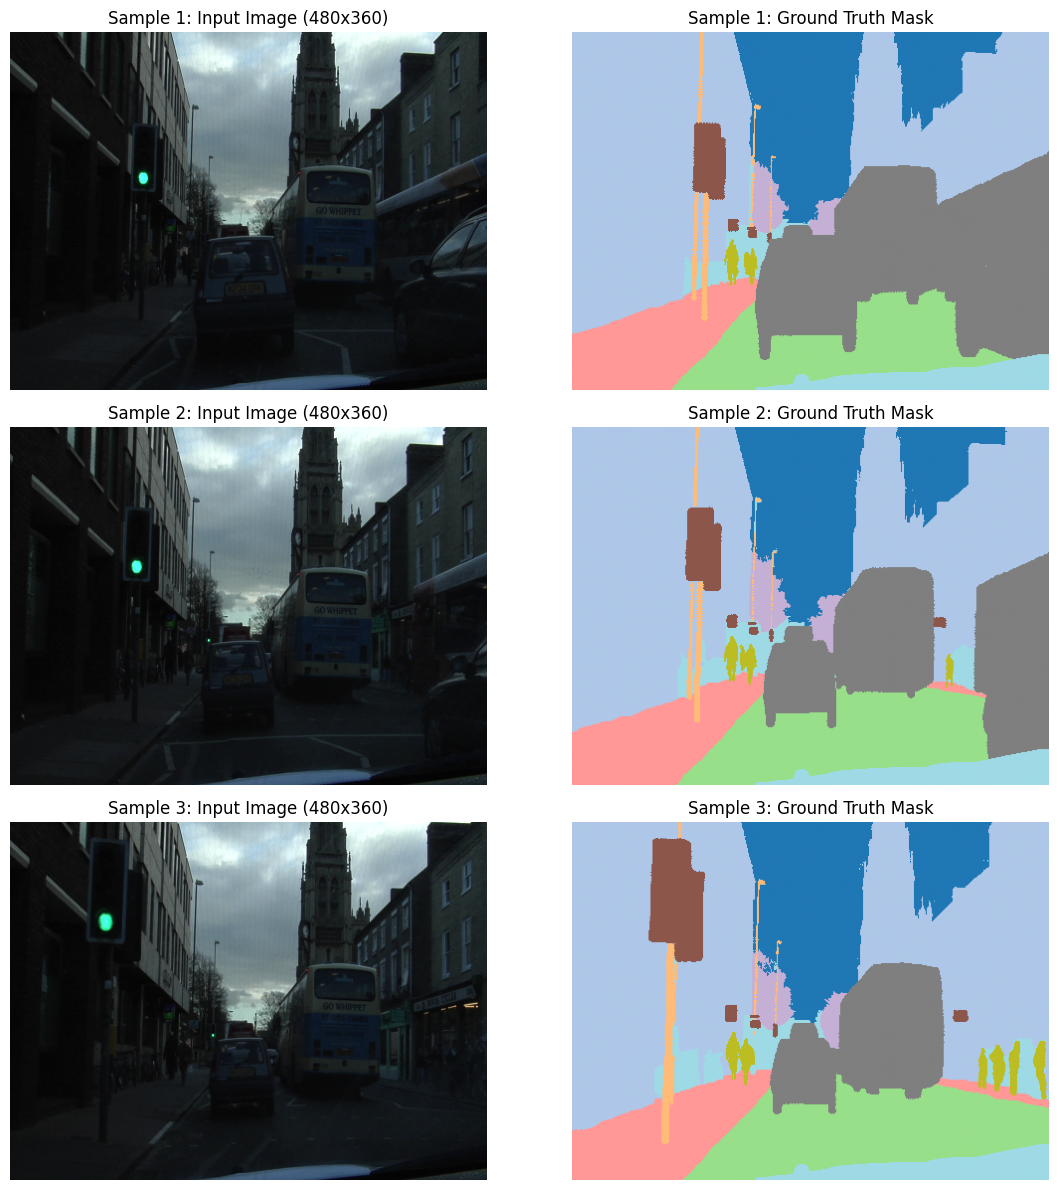

In [9]:
import cv2
import matplotlib.pyplot as plt

def display_sample_pairs(df: pd.DataFrame, num_samples: int = 3):
    """
    Displays side-by-side comparisons of raw driving images and ground truth masks.
    """
    fig, axes = plt.subplots(num_samples, 2, figsize=(12, 4 * num_samples))

    for i in range(num_samples):
        img_path = df.iloc[i]['image_path']
        mask_path = df.iloc[i]['mask_path']

        # Read BGR image and convert to RGB safely
        img_bgr = cv2.imread(img_path)
        if img_bgr is None:
            print(f"[ERROR] Could not read image at: {img_path}")
            continue

        img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

        # Read segmentation mask in grayscale
        mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)

        # Plot RGB Image
        axes[i, 0].imshow(img_rgb)
        axes[i, 0].set_title(f"Sample {i+1}: Input Image ({img_rgb.shape[1]}x{img_rgb.shape[0]})")
        axes[i, 0].axis('off')

        # Plot Ground Truth Mask
        axes[i, 1].imshow(mask, cmap='tab20')
        axes[i, 1].set_title(f"Sample {i+1}: Ground Truth Mask")
        axes[i, 1].axis('off')

    plt.tight_layout()
    plt.show()

# Visualize 3 samples from the training set
display_sample_pairs(df_train, num_samples=3)

4

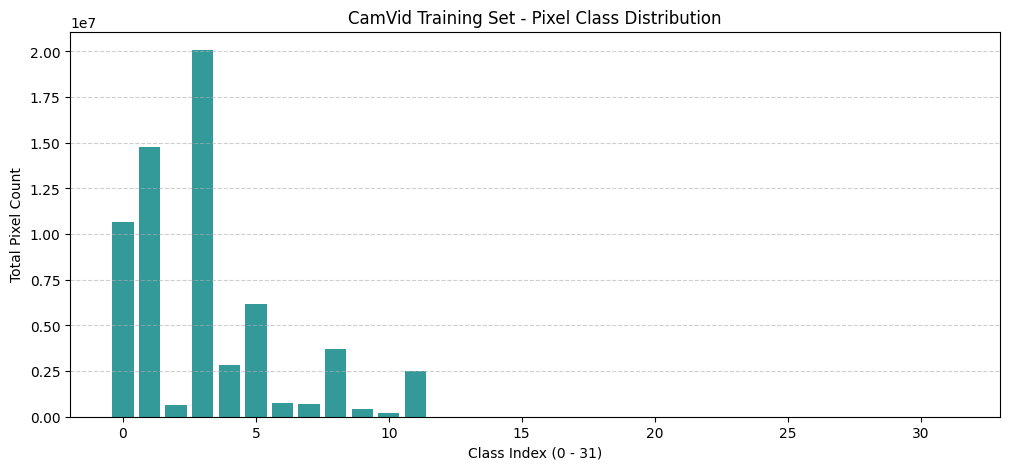

In [10]:
import numpy as np

def analyze_class_frequencies(df: pd.DataFrame, num_classes: int = 32):
    """
    Computes total pixel counts per class index across all masks in the split.
    """
    pixel_counts = np.zeros(num_classes, dtype=np.int64)

    for mask_path in df['mask_path']:
        mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
        if mask is not None:
            uniques, counts = np.unique(mask, return_counts=True)
            for u, c in zip(uniques, counts):
                if u < num_classes:
                    pixel_counts[u] += c

    return pixel_counts

# Calculate class distribution on training set
train_class_counts = analyze_class_frequencies(df_train)

# Plot class pixel distribution
plt.figure(figsize=(12, 5))
plt.bar(range(len(train_class_counts)), train_class_counts, color='teal', alpha=0.8)
plt.xlabel("Class Index (0 - 31)")
plt.ylabel("Total Pixel Count")
plt.title("CamVid Training Set - Pixel Class Distribution")
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.show()